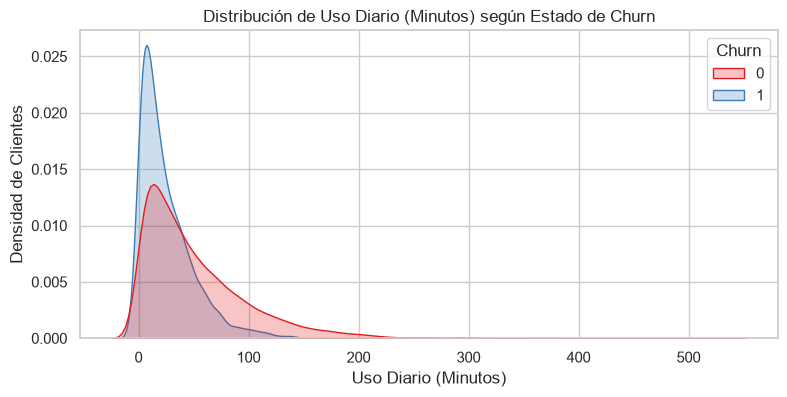

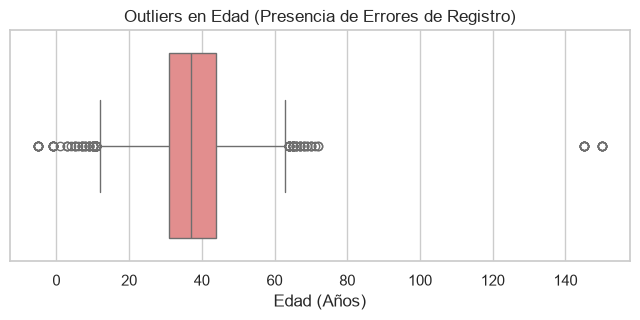

Outliers en Edad detectados:
    ID_Cliente  Edad
70    CLI-6323   150
119   CLI-5071     5
122   CLI-8952    17
206   CLI-8907    16
272  CLI-10275    14
399   CLI-1014    17
456   CLI-4007     9
469   CLI-1483    -5
478   CLI-5929    13
536   CLI-9001   145


In [2]:
# 1. Gráfico de Validación de Hipótesis: Uso Diario vs Churn
plt.figure(figsize=(9, 4))
sns.kdeplot(data=df, x='Uso_Diario_Min', hue='Churn', common_norm=False, fill=True, palette='Set1')
plt.title('Distribución de Uso Diario (Minutos) según Estado de Churn')
plt.xlabel('Uso Diario (Minutos)')
plt.ylabel('Densidad de Clientes')
plt.show()

# 2. Detección de Outliers en Edad
plt.figure(figsize=(8, 3))
sns.boxplot(x=df['Edad'], color='lightcoral')
plt.title('Outliers en Edad (Presencia de Errores de Registro)')
plt.xlabel('Edad (Años)')
plt.show()

print("Outliers en Edad detectados:")
print(df[(df['Edad'] < 18) | (df['Edad'] > 100)][['ID_Cliente', 'Edad']].head(10))

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Configuración visual
sns.set_theme(style="whitegrid")
plt.rcParams["figure.figsize"] = (8, 4)

# Cargar dataset desde la carpeta data
df = pd.read_csv('../data/datacloud_churn.csv')

print("=== DIAGNÓSTICO GENERAL DEL DATASET ===")
print(f"Dimensiones: {df.shape[0]} filas × {df.shape[1]} columnas\n")

print("--- Tipos de Datos e Info ---")
print(df.info())

print("\n--- Conteo de Duplicados y Nulos ---")
print(f"Filas duplicadas (por ID_Cliente): {df['ID_Cliente'].duplicated().sum()}")
print("Valores nulos por columna:")
print(df.isnull().sum())

print("\n--- Balanceo de la Variable Objetivo (Churn) ---")
print(df['Churn'].value_counts(normalize=True) * 100)

Matplotlib is building the font cache; this may take a moment.


=== DIAGNÓSTICO GENERAL DEL DATASET ===
Dimensiones: 10000 filas × 9 columnas

--- Tipos de Datos e Info ---
<class 'pandas.DataFrame'>
RangeIndex: 10000 entries, 0 to 9999
Data columns (total 9 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   ID_Cliente        9990 non-null   str    
 1   Edad              10000 non-null  int64  
 2   Antiguedad_Meses  10000 non-null  str    
 3   Soporte_Tickets   9500 non-null   float64
 4   Uso_Diario_Min    10000 non-null  float64
 5   Monto_Mensual     10000 non-null  float64
 6   Genero            10000 non-null  str    
 7   Region            10000 non-null  str    
 8   Churn             10000 non-null  int64  
dtypes: float64(3), int64(2), str(4)
memory usage: 703.3 KB
None

--- Conteo de Duplicados y Nulos ---
Filas duplicadas (por ID_Cliente): 49
Valores nulos por columna:
ID_Cliente           10
Edad                  0
Antiguedad_Meses      0
Soporte_Tickets     500
Uso_Diario_Min

# FASE 1: Fundamentos de Ciencia de Datos & EDA (CRISP-DM)
**Proyecto:** Sistema Predictivo y Prescriptivo de Abandono de Clientes (Churn)
**Empresa:** DataCloud Solutions

## 1. Modelado del Problema
* **Objetivo de Negocio:** Predecir la cancelación de clientes B2B en los próximos 30 días para implementar acciones de retención oportunas.
* **Métrica Técnica Principal:** Se prioriza **Recall (Sensibilidad)** y **F1-Score** sobre *Accuracy*. Dado el desbalance de clases (~77% activos / ~23% abandono), un modelo iluso que clasifique a todos como activos obtendría 77% de Accuracy pero fallaría en detectar el 100% de la fuga de ingresos.